#### 1. Import Libaries

In [22]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

# Import torch/transformers FIRST
import torch
from transformers import pipeline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from transformers import AutoTokenizer, AutoModelForSequenceClassification

#### 2. data loading

In [2]:
df = pd.read_csv("PSN_articles.csv")

print(df.shape)

df

(193, 7)


,title,source,published,google_link,url,text,text_for_sentiment
0,Pemkab Ketapang Gandeng PSN Hadirkan Internet ...,Pontianak Post,2026-07-09 07:00:00+00:00,https://news.google.com/rss/articles/CBMi6wFBV...,https://pontianakpost.jawapos.com/ketapang/260...,NaN,Pemkab Ketapang Gandeng PSN Hadirkan Internet ...
1,PSN dan Telkomsat Ajukan Slot Orbit Satelit LE...,Bisnis Tekno,2026-07-08 07:00:00+00:00,https://news.google.com/rss/articles/CBMiywFBV...,https://teknologi.bisnis.com/read/20260708/101...,NaN,PSN dan Telkomsat Ajukan Slot Orbit Satelit LE...
2,"Dominasi Starlink Makin Kuat, PSN Sebut Era Sa...",Bisnis Tekno,2026-06-02 07:00:00+00:00,https://news.google.com/rss/articles/CBMizwFBV...,https://teknologi.bisnis.com/read/20260602/101...,NaN,"Dominasi Starlink Makin Kuat, PSN Sebut Era Sa..."
3,🛰️ Indonesia’s Nusantara Lima begins operation...,The Southeast Asia Desk,2026-05-19 07:00:00+00:00,https://news.google.com/rss/articles/CBMie0FVX...,https://www.thesoutheastasiadesk.com/p/indones...,🎯 The Main Takeaway\nIndonesia’s newest satell...,🎯 The Main Takeaway\nIndonesia’s newest satell...
4,Foto Bisnis SWA: Peresmian Operasional Satelit...,SWA.co.id,2026-05-17 07:00:00+00:00,https://news.google.com/rss/articles/CBMilAFBV...,https://swa.co.id/read/472659/foto-bisnis-swa-...,Foto Bisnis SWA: Peresmian Operasional Satelit...,Foto Bisnis SWA: Peresmian Operasional Satelit...
...,...,...,...,...,...,...,...
188,PSN-6 satellite (SSL),Teslarati,2019-01-15 12:19:49+00:00,https://news.google.com/rss/articles/CBMitgFBV...,https://www.teslarati.com/spacex-falcon-9-luna...,Elon Musk just confirmed the Tesla and SpaceX ...,Elon Musk just confirmed the Tesla and SpaceX ...
189,PSN Siap Luncurkan Satelit PSN VI Berkapasitas...,CNN Indonesia,2017-12-07 08:00:00+00:00,https://news.google.com/rss/articles/CBMiuwFBV...,https://www.cnnindonesia.com/teknologi/2017120...,"Jakarta, CNN Indonesia -- PT Pasifik Satelit N...","Jakarta, CNN Indonesia -- PT Pasifik Satelit N..."
190,"Bangun Satelit PALAPA-N1, PT Pasifik Satelit N...",JPNN.com,2017-05-22 07:00:00+00:00,https://news.google.com/rss/articles/CBMiqgFBV...,https://www.jpnn.com/news/bangun-satelit-palap...,"Bangun Satelit PALAPA-N1, PT Pasifik Satelit N...","Bangun Satelit PALAPA-N1, PT Pasifik Satelit N..."
191,Indosat-PSN beli satelit Palapa-N1 dari perusa...,ANTARA News,2017-05-17 07:00:00+00:00,https://news.google.com/rss/articles/CBMingFBV...,https://www.antaranews.com/berita/629703/indos...,Bisnis satelit itu bukan bisnis yang kita ngom...,Bisnis satelit itu bukan bisnis yang kita ngom...


#### 3. EDA

##### Dataframe info

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   title               193 non-null    object
 1   source              193 non-null    object
 2   published           193 non-null    object
 3   google_link         193 non-null    object
 4   url                 193 non-null    object
 5   text                160 non-null    object
 6   text_for_sentiment  193 non-null    object
dtypes: object(7)
memory usage: 10.7+ KB


In [4]:
df.isnull().sum()

title                  0
source                 0
published              0
google_link            0
url                    0
text                  33
text_for_sentiment     0
dtype: int64

##### Checking Duplicates

In [5]:
df["title"].str.lower().str.strip().duplicated().sum()

0

In [6]:
df["url"].duplicated().sum()

0

##### Dates of article published

In [7]:
# converting time to datetime
df["published"] = pd.to_datetime(df["published"], utc=True)
df["year"] = df["published"].dt.year

In [8]:
# showing articles from oldest to newest
print(df["published"].min())
print(df["published"].max())

2017-05-17 07:00:00+00:00
2026-07-09 07:00:00+00:00


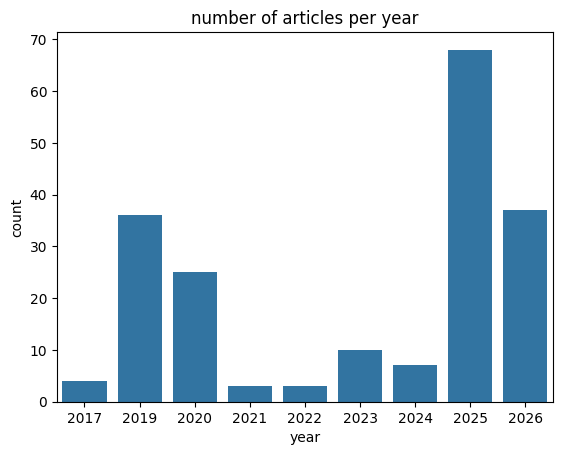

In [9]:
# number of articles per year
sns.countplot(data=df, x="year")
plt.title("number of articles per year")
plt.show()

##### Articles sources that dominates the most

In [10]:
print(df["source"].nunique())
df["source"].value_counts().head(10)

75


source
detikInet        34
Bisnis Tekno     13
Kompas.id        10
Suara.com        10
Tempo.co          9
Kumparan.com      9
ANTARA News       7
Kompas.com        6
InvestorTrust     5
kontan.co.id      4
Name: count, dtype: int64

##### The length of text 

count     193.0
mean      363.0
std       310.0
min         7.0
25%       124.0
50%       328.0
75%       511.0
max      1688.0
Name: word_count, dtype: float64


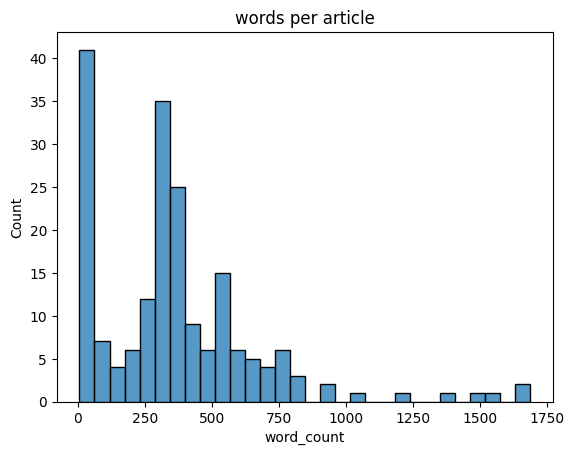

In [11]:
df["word_count"] = df["text_for_sentiment"].str.split().str.len()

print(df["word_count"].describe().round(0))

sns.histplot(data=df, x="word_count", bins=30)
plt.title("words per article")
plt.show()

here we can explore on how many articles that have only a title and how many that are fewer than 30 words from data scraping

In [12]:
print("title only:", df["text"].isnull().sum())

title only: 33


In [13]:
print("fewer than 30 words:", (df["word_count"] < 30).sum())

fewer than 30 words: 33


##### Finding what language the data dominates

In [14]:
first_part = df["text_for_sentiment"].str.lower().str[:500]
df["indo_words"] = first_part.str.count(r"\b(?:yang|dan|untuk|dengan|dari|pada|ini|satelit)\b")

df["language"] = np.where(df["indo_words"] >=3, "Indonesian", "English/other")

df["language"].value_counts()

language
Indonesian       141
English/other     52
Name: count, dtype: int64

##### Validating if the articles are about psn

In [15]:
keywords = "PSN|Pasifik Satelit|Pacific Satelite|Nusantara"
df["mentions_psn"] = df["text_for_sentiment"].str.contains(keywords, case=False, regex=True)

print(df["mentions_psn"].value_counts())

df[~df["mentions_psn"]][["title", "source"]]

mentions_psn
True     190
False      3
Name: count, dtype: int64


,title,source
37,Adi Rahman Adiwoso Raih Penghargaan Aerospace ...,Bisnis Tekno
127,"Adi Rahman Adiwoso, Teknologiwan Indonesia yan...",nukilan.id
188,PSN-6 satellite (SSL),Teslarati


#### 4. Data cleaning

the text from data scrapping is almost a mess with line breaks, extra spaces, duplicate and empty texts. this aims to clean the said text

In [16]:
# this cell will be for text cleaning

df["clean_text"] = df["text_for_sentiment"]

# replace line breaks with space
df["clean_text"] = df["clean_text"].str.replace("\n", " ", regex=True)

# removing domains
df["clean_text"] = df["clean_text"].str.replace("Dilarang keras mengambil konten.*?(?:situs web ini [.]|ANTARA[.])", "", regex=True)

# removing links
df["clean_text"] = df["clean_text"].str.replace("https?://[^ ]+", "", regex=True)

# change spaces into one space
df["clean_text"] = df["clean_text"].str.replace(" +", " ", regex=True)

# remove spaces at the start sentence and at the end of the sentence
df["clean_text"] = df["clean_text"].str.strip()

In [17]:
# Removing duplicate articles 
rows_before = df.shape[0]
df = df.drop_duplicates(subset="title")

# Removing articles if the content is none after cleaning
df = df[df["clean_text"].str.len() > 0]

# Reset row numbers after cleaning
df = df.reset_index(drop=True)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype              
---  ------              --------------  -----              
 0   title               193 non-null    object             
 1   source              193 non-null    object             
 2   published           193 non-null    datetime64[ns, UTC]
 3   google_link         193 non-null    object             
 4   url                 193 non-null    object             
 5   text                160 non-null    object             
 6   text_for_sentiment  193 non-null    object             
 7   year                193 non-null    int32              
 8   word_count          193 non-null    int64              
 9   indo_words          193 non-null    int64              
 10  language            193 non-null    object             
 11  mentions_psn        193 non-null    bool               
 12  clean_text          193 non-null    

checking the result of text before and after cleaning

In [18]:
print("Before:", round(df["text_for_sentiment"].str.len().mean()), "characters")
print("After:", round(df["clean_text"].str.len().mean()), "characters")

Before: 2675 characters
After: 2643 characters


#### 5. adding lables using pre-trained sentiment model

##### Loading the model



the data i scraped doesn't come with sentiment, so i do a workaround by using a pre-trained sentiment model.

here i will be using ```lxyuan_distilbert``` and ```xlm_roberta``` to compare and to decide which one is better for labeling the PSN articles. I compare their label counts, agreement, and confidence scores

In [ ]:

lxyuan_distilbert_classifier = pipeline(
    "sentiment-analysis",
    model="lxyuan/distilbert-base-multilingual-cased-sentiments-student"
)

Device set to use cpu


In [37]:
tokenizer = AutoTokenizer.from_pretrained("xlm-roberta-base")
model = AutoModelForSequenceClassification.from_pretrained("cardiffnlp/twitter-xlm-roberta-base-sentiment")

xlm_roberta_base = pipeline(
    "sentiment-analysis", 
    model=model, 
    tokenizer=tokenizer)

Device set to use cpu


In [38]:
texts = df["clean_text"].tolist()

#loading two models
distilbert_result = lxyuan_distilbert_classifier(texts, truncation=True, max_length=512, batch_size=8)
xlm_result = xlm_roberta_base(texts, truncation=True, max_length=512)

##### Label Comparison on each models

In [27]:
# put both results into a seperate table
compare_df = pd.DataFrame({
    "text": texts,
    "label_distilbert": pd.DataFrame(distilbert_result)["label"].str.lower(),
    "score_distilbert": pd.DataFrame(distilbert_result)["score"],
    "label_xlm": pd.DataFrame(xlm_result)["label"].str.lower(),
    "score_xlm": pd.DataFrame(xlm_result)["score"]
})

compare_df.head(10)


,text,label_distilbert,score_distilbert,label_xlm,score_xlm
0,Pemkab Ketapang Gandeng PSN Hadirkan Internet ...,positive,0.546819,positive,0.579546
1,PSN dan Telkomsat Ajukan Slot Orbit Satelit LE...,positive,0.545614,neutral,0.703243
2,"Dominasi Starlink Makin Kuat, PSN Sebut Era Sa...",positive,0.660443,positive,0.473927
3,🎯 The Main Takeaway Indonesia’s newest satelli...,positive,0.467914,neutral,0.460888
4,Foto Bisnis SWA: Peresmian Operasional Satelit...,positive,0.551659,neutral,0.721646
5,Can't find what you're looking for? View all s...,positive,0.635248,neutral,0.461794
6,The Nusantara Lima Satellite has officially co...,positive,0.821756,neutral,0.422207
7,Satelit Nusantara Lima Menjadi Satelit Terbesa...,positive,0.555935,neutral,0.657592
8,"PSN Gelontorkan Investasi Lebih Rp 23 Triliun,...",positive,0.729301,neutral,0.531458
9,"Tantang Starlink, PSN Andalkan Satelit Lokal d...",positive,0.598618,neutral,0.558645


##### Label distribution
here, i want to see the difference of sentiment distribution by comparing each label on each model

In [ ]:
# showing the comparison dataframe
pd.DataFrame({
    "distilbert": compare_df["label_distilbert"].value_counts(),
    "xlm": compare_df["label_xlm"].value_counts()
})

,distilbert,xlm
negative,32,4
neutral,2,177
positive,159,12


based on this result, Distilbert has 159 positive, but xlm has 177 neutral. the two models labels the data very differently.

##### Comparing confidence score
here i will be comparing both confidence scores, the higher the score the better the model at labeling

In [31]:
print("DistilBERT avg score:", compare_df["score_distilbert"].mean())
print("XLM avg score:", compare_df["score_xlm"].mean())

DistilBERT avg score: 0.6558425233462931
XLM avg score: 0.5616082382325681


The average confidence is close: DistilBERT is 0.66 and XLM is 0.56. Both scores are fairly low, which means neither model is very sure about its labels on these news articles. Confidence alone cannot tell me which model is better.

##### Checking accuracy with manual label set.

since confidence score isn't enough to measure which model will be used. i will try to get model accuracy by manually labeling a small random sampel of articles and then comparing it with the pre trained model

In [45]:
gold = compare_df.sample(60, random_state=42).copy()
gold["true_label"] = None

In [ ]:
# label the articles one by one
# 1 = positive, 2 = neutral, 3 = negative, q = stop (you can run this cell again to continue)
choices = {"1": "positive", "2": "neutral", "3": "negative"}

for i in gold.index:
    if pd.notna(gold.loc[i, "true_label"]):
        continue  # already labeled

    print("-" * 80)
    print(f"[{i}]", df.loc[i, "title"])
    print(gold.loc[i, "text"][:500])

    answer = input("1 = positive, 2 = neutral, 3 = negative, q = stop: ")
    while answer != "q" and answer not in choices:
        answer = input("please type 1, 2, 3 or q: ")

    if answer == "q":
        break
    gold.loc[i, "true_label"] = choices[answer]

gold.to_csv("gold_set.csv")  # saves your progress
print("labeled so far:", gold["true_label"].notna().sum(), "/", len(gold))2

--------------------------------------------------------------------------------
[45] Setelah Mengorbit, Apa Manfaat Satelit Nusantara Lima bagi Indonesia?
Kemajuan sebuah bangsa identik dengan penguasaan teknologi luar angkasa. Satelit Nusantara Lima diharapkan memberi manfaat dalam hal teknologi komunikasi RI. 15 Sep 2025 08:01 WIB · Ekonomi & Bisnis (1) Mengapa Indonesia membutuhkan teknologi satelit? (2) Sebelum Nusantara Lima, kapan Indonesia pertama kali meluncurkan satelit? (3) Apa saja manfaat satelit Nusantara Lima bagi Indonesia? (4) Apakah Indonesia sudah memiliki kemampuan teknologi membangun satelit sendiri? Menurut laman resmi Badan P
--------------------------------------------------------------------------------
[137] Satelit Nusantara Dua Gagal Mengorbit, Layanan Penyiaran Tetap Aman
JAKARTA, KOMPAS.com - Satelit Nusantara Dua yang meluncur dari Xichang Satellite Launch Center (XLSC) di Xichang, China, Kamis (9/4/2020) malam pukul 19.46 WIB, gagal mengorbit. Kegagalan 

DISTILBERT
accuracy: 0.5
macro F1: 0.316
              precision    recall  f1-score   support

    negative       0.50      0.24      0.32        21
     neutral       0.00      0.00      0.00         8
    positive       0.51      0.81      0.62        31

    accuracy                           0.50        60
   macro avg       0.34      0.35      0.32        60
weighted avg       0.44      0.50      0.44        60



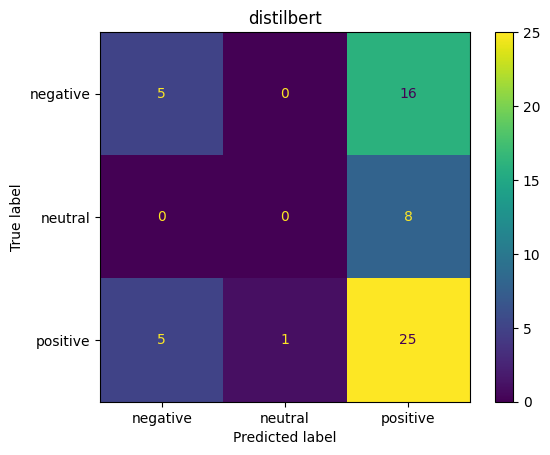

XLM
accuracy: 0.167
macro F1: 0.142
              precision    recall  f1-score   support

    negative       0.50      0.05      0.09        21
     neutral       0.13      0.88      0.23         8
    positive       0.50      0.06      0.11        31

    accuracy                           0.17        60
   macro avg       0.38      0.33      0.14        60
weighted avg       0.45      0.17      0.12        60



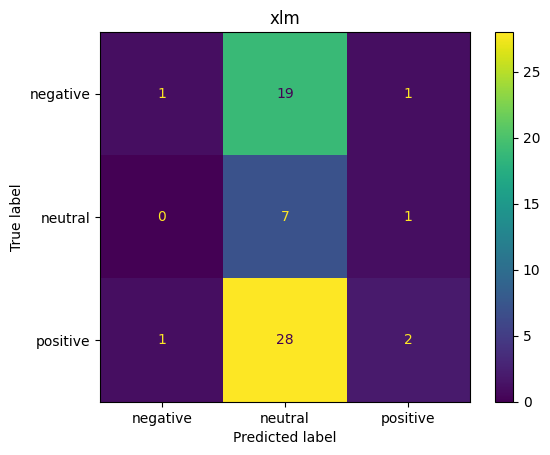

In [47]:
# only use the articles that i have labeled
labeled = gold.dropna(subset=["true_label"])
label_order = ["negative", "neutral", "positive"]

for name in ["distilbert", "xlm"]:
    pred = labeled["label_" + name]

    print(name.upper())
    print("accuracy:", round(accuracy_score(labeled["true_label"], pred), 3))
    print("macro F1:", round(f1_score(labeled["true_label"], pred, average="macro"), 3))
    print(classification_report(labeled["true_label"], pred, zero_division=0))

    ConfusionMatrixDisplay.from_predictions(labeled["true_label"], pred, labels=label_order)
    plt.title(name)
    plt.show()

In [ ]:
df["sentiment"] = compare_df["label_xlm"]  
df["score"] = compare_df["score_xlm"] 